# Final Gutenberg Corpus Selection

This notebook applies the final record-level corpus filters: publication-year checks, duplicate removal, multi-volume consolidation, author-level book caps, temporal and genre summaries, and Armstrong core-set reconciliation. It is preserved from the original research environment, so historical input filenames and intermediate diagnostic cells remain unchanged.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_colwidth', None)


In [5]:
df = pd.read_csv('british_books_with_years_final.csv')
#df.rename(columns={'LLM_first_last_gemma': 'publication_year'}, inplace=True)
#df.set_index('id', inplace=True)
df.head(5)

,gutenberg_id,title,publication_year,author_raw,author_display,author_query,gender,nationality,subjects,subject_text,...,is_manual_resolution,place,wd_birthYears,wd_deathYear,wd_gender,wd_tier,wd_all_tiers,wd_places,wd_is_uk,wd_colonial_only
0,21233,"""All's Well""; or, Alice's Victory",1893,"Holt, Emily Sarah, 1836-1893",Emily Sarah Holt,Emily Sarah Holt,female,British,Historical fiction; Counter-Reformation -- England -- Fiction,historical fiction; counter-reformation -- england -- fiction,...,False,NaN,[1836],1893.0,female,no_p27,['no_p27'],[],False,False
1,2186,"""Captains Courageous"": A Story of the Grand Banks",1902,"Kipling, Rudyard, 1865-1936",Rudyard Kipling,Rudyard Kipling,male,British,Sea stories; Bildungsromans; Children of the rich -- Fiction; Saltwater fishing -- Fiction; Fishing boats -- Fiction; Teenage boys -- Fiction; Rescues -- Fiction; Fishers -- Fiction; Grand Banks of Newfoundland -- Fiction,sea stories; bildungsromans; children of the rich -- fiction; saltwater fishing -- fiction; fishing boats -- fiction; teenage boys -- fiction; rescues -- fiction; fishers -- fiction; grand banks of newfoundland -- fiction,...,False,United Kingdom | United Kingdom of Great Britain and Ireland,[1865],1936.0,male,core,['core'],"['United Kingdom', 'United Kingdom of Great Britain and Ireland']",True,False
2,1629,"""I Say No""",1860,"Collins, Wilkie, 1824-1889",Wilkie Collins,Wilkie Collins,male,British,Great Britain -- Social life and customs -- 19th century -- Fiction; Mystery fiction,great britain -- social life and customs -- 19th century -- fiction; mystery fiction,...,False,United Kingdom of Great Britain and Ireland,[1824],1889.0,male,core,['core'],['United Kingdom of Great Britain and Ireland'],True,False
3,23329,"""Le Monsieur de la Petite Dame""",1877,"Burnett, Frances Hodgson, 1849-1924",Frances Hodgson Burnett,Frances Hodgson Burnett,female,British,Manners and customs -- Fiction; Man-woman relationships -- Fiction,manners and customs -- fiction; man-woman relationships -- fiction,...,False,United Kingdom | United Kingdom of Great Britain and Ireland | United States,[1849],1924.0,female,core,"['america', 'core']","['United Kingdom', 'United Kingdom of Great Britain and Ireland', 'United States']",True,False
4,7714,"""My Novel"" — Complete",1853,"Lytton, Edward Bulwer Lytton, Baron, 1803-1873",Edward Bulwer Lytton,Edward Bulwer Lytton,male,British,Germany -- Fiction; England -- Fiction; Domestic fiction; Inventors -- Fiction; Poets -- Fiction; Death -- Fiction; Rhine River -- Fiction,germany -- fiction; england -- fiction; domestic fiction; inventors -- fiction; poets -- fiction; death -- fiction; rhine river -- fiction,...,False,United Kingdom of Great Britain and Ireland,[1803],1873.0,male,core,['core'],['United Kingdom of Great Britain and Ireland'],True,False


In [6]:
df.columns

Index(['gutenberg_id', 'title', 'publication_year', 'author_raw',
       'author_display', 'author_query', 'gender', 'nationality', 'subjects',
       'subject_text', 'is_domestic', 'is_detective_mystery',
       'is_science_fiction', 'is_adventure', 'is_gothic', 'is_historical',
       'has_major_genre', 'genre_tags', 'broad_group', 'author_key_normalized',
       'author_display_normalized', 'is_canonical_author', 'canonical_period',
       'is_english_fiction_19c', 'is_general_19c_candidate', 'auto_group',
       'has_fiction_signal', 'wd_qid', 'wd_writer', 'match_rule', 'is_matched',
       'resolution_status', 'is_manual_resolution', 'place', 'wd_birthYears',
       'wd_deathYear', 'wd_gender', 'wd_tier', 'wd_all_tiers', 'wd_places',
       'wd_is_uk', 'wd_colonial_only'],
      dtype='object')

In [7]:
df['auto_group'].value_counts()

,count
auto_group,
non_domestic_genre,1306
core_domestic,671
general_19c_english,296
canonical_other,204
domestic_adjacent_hybrid,57


In [8]:
df['genre_tags'].value_counts()

,count
genre_tags,
detective_mystery,479
adventure,404
historical,242
gothic,89
science_fiction,77
adventure; historical,31
detective_mystery; adventure,18
science_fiction; gothic,7
gothic; historical,4


## Inspect missing publication years


In [9]:
df['publication_year'].isna().sum()

np.int64(0)

In [10]:
df[['title','author_display', 'publication_year', 'auto_group','genre_tags']].sort_values('publication_year').head(30)

,title,author_display,publication_year,auto_group,genre_tags
1531,The Fortunate Mistress (Parts 1 and 2)\nor a History of the Life of Mademoiselle de Beleau Known by the Name of the Lady Roxana,Daniel Defoe,1704,non_domestic_genre,adventure; historical
1541,The Further Adventures of Robinson Crusoe,Daniel Defoe,1719,non_domestic_genre,adventure
863,Memoirs of Major Alexander Ramkins (1718),Daniel Defoe,1719,non_domestic_genre,adventure
1723,The Life and Adventures of Robinson Crusoe,Daniel Defoe,1719,non_domestic_genre,adventure
1724,"The Life, Adventures & Piracies of the Famous Captain Singleton",Daniel Defoe,1720,non_domestic_genre,adventure
1696,"The King of Pirates\nBeing an Account of the Famous Enterprises of Captain Avery, the Mock King of Madagascar",Daniel Defoe,1720,non_domestic_genre,adventure
862,"Memoirs of a Cavalier\nA Military Journal of the Wars in Germany, and the Wars in England.\nFrom the Year 1632 to the Year 1648.",Daniel Defoe,1720,non_domestic_genre,historical
1532,The Fortunes and Misfortunes of the Famous Moll Flanders,Daniel Defoe,1722,non_domestic_genre,adventure
603,History of the Plague in London,Daniel Defoe,1722,non_domestic_genre,historical
68,"A Journal of the Plague Year\nBeing Observations or Memorials of the Most Remarkable Occurrences, as Well Public as Private, Which Happened in London During the Last Great Visitation in 1665. Written by a Citizen Who Continued All the While in London",Daniel Defoe,1722,non_domestic_genre,historical


In [11]:
df.groupby('author_display').size().sort_values(ascending=False).head(20)

,0
author_display,
Edward Bulwer Lytton,130
George Meredith,86
Fergus Hume,57
William Le Queux,57
E. Phillips Oppenheim,49
M. E. Braddon,46
Walter Scott,43
R. M. Ballantyne,42
G. A. Henty,41


## Corpus cleaning


### Remove duplicate records


In [12]:
import re

df_clean = df.copy()

df_clean["gutenberg_id"] = pd.to_numeric(
    df_clean["gutenberg_id"],
    errors="coerce"
)

df_clean["author_exact_key"] = (
    df_clean["author_display"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.casefold()
)

df_clean["title_exact_key"] = (
    df_clean["title"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.casefold()
)

In [13]:
df_clean = df_clean.sort_values(
    ["author_exact_key", "title_exact_key", "gutenberg_id"]
).copy()

df_clean["exact_duplicate_rank"] = (
    df_clean
    .groupby(
        ["author_exact_key", "title_exact_key"],
        dropna=False
    )
    .cumcount()
)

df_clean["is_exact_duplicate"] = (
    df_clean["exact_duplicate_rank"] > 0
)

exact_duplicate_groups = (
    df_clean
    .groupby(
        ["author_exact_key", "title_exact_key"],
        dropna=False
    )
    .filter(lambda x: len(x) > 1)
    [
        [
            "gutenberg_id",
            "title",
            "author_display",
            "publication_year",
            "exact_duplicate_rank",
        ]
    ]
    .sort_values(["author_display", "title", "gutenberg_id"])
)

exact_duplicate_groups

,gutenberg_id,title,author_display,publication_year,exact_duplicate_rank
250,2432,Barchester Towers,Anthony Trollope,1857,0
251,3409,Barchester Towers,Anthony Trollope,1857,1
1087,5148,Rodney Stone,Arthur Conan Doyle,1921,0
1086,36050,Rodney Stone,Arthur Conan Doyle,1896,1
1648,2852,The Hound of the Baskervilles,Arthur Conan Doyle,1902,0
...,...,...,...,...,...
2036,17500,The Return of the Native,Thomas Hardy,1912,1
2463,2034,"Waverley; or, 'Tis sixty years since",Walter Scott,1814,0
2464,5998,"Waverley; or, 'Tis sixty years since",Walter Scott,1893,1
2365,41187,This House to Let,William Le Queux,1921,0


In [14]:
df_exact_duplicates_removed = (
    df_clean[df_clean["is_exact_duplicate"]]
    [
        [
            "gutenberg_id",
            "title",
            "author_display",
            "publication_year",
            "exact_duplicate_rank",
        ]
    ]
    .sort_values(["author_display", "title", "gutenberg_id"])
    .reset_index(drop=True)
)

print("Exact duplicate editions removed:",
      len(df_exact_duplicates_removed))

df_exact_duplicates_removed

Exact duplicate editions removed: 50


,gutenberg_id,title,author_display,publication_year,exact_duplicate_rank
0,3409,Barchester Towers,Anthony Trollope,1857,1
1,36050,Rodney Stone,Arthur Conan Doyle,1896,1
2,3070,The Hound of the Baskervilles,Arthur Conan Doyle,1902,1
3,3776,The Valley of Fear,Arthur Conan Doyle,1915,1
4,45839,Dracula,Bram Stoker,1897,1
5,47634,Sons and Lovers,D. H. Lawrence,1913,1
6,44262,The Spanish brothers,Deborah Alcock,1888,1
7,2946,Howards End,E. M. Forster,1910,1
8,57539,Cranford,Elizabeth Cleghorn Gaskell,1891,1
9,70506,The family at Misrule,Ethel Turner,1895,1


In [15]:
df_dedup = (
    df_clean[~df_clean["is_exact_duplicate"]]
    .copy()
    .reset_index(drop=True)
)

print("Before exact deduplication:", len(df_clean))
print("After exact deduplication:", len(df_dedup))

Before exact deduplication: 2534
After exact deduplication: 2484


### Identify multi-volume families


In [16]:
NUMBER_WORDS = (
    r"one|two|three|four|five|six|seven|eight|nine|ten|"
    r"eleven|twelve"
)

ROMAN_PATTERN = r"[ivxlcdm]+"
ARABIC_PATTERN = r"\d{1,3}"
VOLUME_NUMBER_PATTERN = rf"(?:{ARABIC_PATTERN}|{ROMAN_PATTERN})"

def roman_to_int(value):
    if pd.isna(value):
        return pd.NA

    value = str(value).strip().upper()

    if value.isdigit():
        return int(value)

    roman_values = {
        "I": 1,
        "V": 5,
        "X": 10,
        "L": 50,
        "C": 100,
        "D": 500,
        "M": 1000,
    }

    if not value or any(ch not in roman_values for ch in value):
        return pd.NA

    total = 0
    previous = 0

    for ch in reversed(value):
        current = roman_values[ch]

        if current < previous:
            total -= current
        else:
            total += current
            previous = current

    return total

In [17]:
def extract_volume_number(title):
    if pd.isna(title):
        return pd.NA

    title = str(title)

    match = re.search(
        rf"\b(?:volume|vol\.?|book)\s*"
        rf"({VOLUME_NUMBER_PATTERN})\b",
        title,
        flags=re.IGNORECASE,
    )

    if not match:
        return pd.NA

    return roman_to_int(match.group(1))

def extract_total_volumes(title):
    if pd.isna(title):
        return pd.NA

    title = str(title)

    # Example: Volume 1 (of 3)
    match = re.search(
        rf"\(\s*of\s*({VOLUME_NUMBER_PATTERN})\s*\)",
        title,
        flags=re.IGNORECASE,
    )

    if match:
        return roman_to_int(match.group(1))

    # Example: In Three Volumes
    match = re.search(
        rf"\bin\s+({NUMBER_WORDS}|\d+)\s+volumes?\b",
        title,
        flags=re.IGNORECASE,
    )

    if not match:
        return pd.NA

    value = match.group(1).lower()

    word_map = {
        "one": 1,
        "two": 2,
        "three": 3,
        "four": 4,
        "five": 5,
        "six": 6,
        "seven": 7,
        "eight": 8,
        "nine": 9,
        "ten": 10,
        "eleven": 11,
        "twelve": 12,
    }

    if value.isdigit():
        return int(value)

    return word_map.get(value, pd.NA)

In [18]:
def make_volume_base_title(title):
    if pd.isna(title):
        return ""

    title = str(title).strip()

    # Normalize dash variants
    title = re.sub(r"[‐-‒–—―]+", " — ", title)

    # Remove trailing "Complete"
    # Examples:
    # "My Novel — Complete"
    # "Volume I, II and III: Complete"
    title = re.sub(
        r"\s*(?:—|[-,:;])?\s*\bcomplete\b\s*[.!]?\s*$",
        "",
        title,
        flags=re.IGNORECASE,
    )

    # Remove phrases such as "In Three Volumes"
    title = re.sub(
        rf"\s*\b(?:in\s+)?"
        rf"(?:{NUMBER_WORDS}|\d+)\s+volumes?\b",
        "",
        title,
        flags=re.IGNORECASE,
    )

    # Remove trailing volume/book section and everything after it
    # Examples:
    # — Volume 01
    # , Vol. 1 (of 3)
    # — Volume I, II and III
    # — Book 01
    title = re.sub(
        rf"\s*(?:—|[-,:;])?\s*"
        rf"\b(?:volume|vol\.?|book)\s*"
        rf"{VOLUME_NUMBER_PATTERN}\b.*$",
        "",
        title,
        flags=re.IGNORECASE,
    )

    # Final punctuation and whitespace cleanup
    title = re.sub(r"\s+", " ", title)
    title = re.sub(r"\s+([,.;:])", r"\1", title)
    title = title.strip(" \t\r\n—-,:;.")

    return title

def normalize_volume_base_title(title):
    title = make_volume_base_title(title)

    title = title.casefold()
    title = re.sub(r"[^a-z0-9\s]", " ", title)
    title = re.sub(r"\s+", " ", title).strip()

    return title

In [19]:
df_volume = df_dedup.copy()

df_volume["is_complete_edition"] = (
    df_volume["title"]
    .fillna("")
    .astype(str)
    .str.contains(
        r"\bcomplete\b",
        case=False,
        regex=True,
        na=False,
    )
)

volume_marker_pattern = (
    rf"\b(?:volume|vol\.?|book)\s*"
    rf"{VOLUME_NUMBER_PATTERN}\b"
)

df_volume["is_volume_part"] = (
    df_volume["title"]
    .fillna("")
    .astype(str)
    .str.contains(
        volume_marker_pattern,
        case=False,
        regex=True,
        na=False,
    )
)

df_volume["has_multi_volume_phrase"] = (
    df_volume["title"]
    .fillna("")
    .astype(str)
    .str.contains(
        rf"\bin\s+(?:{NUMBER_WORDS}|\d+)\s+volumes?\b",
        case=False,
        regex=True,
        na=False,
    )
)

In [20]:
df_volume["volume_number"] = (
    df_volume["title"]
    .apply(extract_volume_number)
    .astype("Int64")
)

df_volume["stated_total_volumes"] = (
    df_volume["title"]
    .apply(extract_total_volumes)
    .astype("Int64")
)

df_volume["volume_base_title"] = (
    df_volume["title"]
    .apply(make_volume_base_title)
)

df_volume["volume_base_title_key"] = (
    df_volume["title"]
    .apply(normalize_volume_base_title)
)

df_volume["is_volume_related"] = (
    df_volume["is_volume_part"]
    | df_volume["is_complete_edition"]
    | df_volume["has_multi_volume_phrase"]
)

In [21]:
df_volume["volume_family_key"] = (
    df_volume["author_exact_key"]
    + " || "
    + df_volume["volume_base_title_key"]
)

df_volume_candidates = df_volume[
    df_volume["is_volume_related"]
].copy()

In [22]:
len(df_volume_candidates)

464

In [23]:
volume_family_summary = (
    df_volume_candidates
    .groupby(
        [
            "volume_family_key",
            "author_exact_key",
            "volume_base_title_key",
        ],
        dropna=False
    )
    .agg(
        author_display=(
            "author_display",
            lambda x: x.dropna().iloc[0] if x.notna().any() else ""
        ),
        volume_base_title=(
            "volume_base_title",
            lambda x: x.dropna().iloc[0] if x.notna().any() else ""
        ),
        n_records=("gutenberg_id", "nunique"),
        n_volume_parts=("is_volume_part", "sum"),
        has_complete=("is_complete_edition", "max"),
        min_publication_year=("publication_year", "min"),
        max_publication_year=("publication_year", "max"),
        gutenberg_ids=(
            "gutenberg_id",
            lambda x: sorted(x.dropna().astype(int).unique().tolist())
        ),
        volume_numbers=(
            "volume_number",
            lambda x: sorted(
                x.dropna().astype(int).unique().tolist()
            )
        ),
        stated_totals=(
            "stated_total_volumes",
            lambda x: sorted(
                x.dropna().astype(int).unique().tolist()
            )
        ),
        titles=(
            "title",
            lambda x: list(dict.fromkeys(x.dropna().astype(str)))
        ),
    )
    .reset_index()
)

In [24]:
volume_families = (
    volume_family_summary[
        volume_family_summary["n_records"] >= 2
    ]
    .sort_values(
        [
            "has_complete",
            "n_records",
            "author_display",
            "volume_base_title",
        ],
        ascending=[False, False, True, True]
    )
    .reset_index(drop=True)
)

In [25]:
print("Candidate volume families:", len(volume_families))

volume_families[
    [
        "author_display",
        "volume_base_title",
        "n_records",
        "n_volume_parts",
        "has_complete",
        "volume_numbers",
        "stated_totals",
        "gutenberg_ids",
        "titles",
    ]
]

Candidate volume families: 103


,author_display,volume_base_title,n_records,n_volume_parts,has_complete,volume_numbers,stated_totals,gutenberg_ids,titles
0,Edward Bulwer Lytton,The Caxtons: A Family Picture,19,18,True,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]",[],"[7586, 7587, 7588, 7589, 7590, 7591, 7592, 7593, 7594, 7595, 7596, 7597, 7598, 7599, 7601, 7602, 7603, 7604, 7605]","[The Caxtons: A Family Picture — Complete, The Caxtons: A Family Picture — Volume 01, The Caxtons: A Family Picture — Volume 02, The Caxtons: A Family Picture — Volume 03, The Caxtons: A Family Picture — Volume 04, The Caxtons: A Family Picture — Volume 05, The Caxtons: A Family Picture — Volume 06, The Caxtons: A Family Picture — Volume 07, The Caxtons: A Family Picture — Volume 08, The Caxtons: A Family Picture — Volume 09, The Caxtons: A Family Picture — Volume 10, The Caxtons: A Family Picture — Volume 11, The Caxtons: A Family Picture — Volume 12, The Caxtons: A Family Picture — Volume 13, The Caxtons: A Family Picture — Volume 14, The Caxtons: A Family Picture — Volume 15, The Caxtons: A Family Picture — Volume 16, The Caxtons: A Family Picture — Volume 17, The Caxtons: A Family Picture — Volume 18]"
1,Edward Bulwer Lytton,"""My Novel""",13,12,True,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",[],"[7702, 7703, 7704, 7705, 7706, 7707, 7708, 7709, 7710, 7711, 7712, 7713, 7714]","[""My Novel"" — Complete, ""My Novel"" — Volume 01, ""My Novel"" — Volume 02, ""My Novel"" — Volume 03, ""My Novel"" — Volume 04, ""My Novel"" — Volume 05, ""My Novel"" — Volume 06, ""My Novel"" — Volume 07, ""My Novel"" — Volume 08, ""My Novel"" — Volume 09, ""My Novel"" — Volume 10, ""My Novel"" — Volume 11, ""My Novel"" — Volume 12]"
2,Edward Bulwer Lytton,The Parisians,13,12,True,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",[],"[7737, 7738, 7739, 7740, 7741, 7742, 7743, 7744, 7745, 7746, 7747, 7748, 7749]","[The Parisians — Complete, The Parisians — Volume 01, The Parisians — Volume 02, The Parisians — Volume 03, The Parisians — Volume 04, The Parisians — Volume 05, The Parisians — Volume 06, The Parisians — Volume 07, The Parisians — Volume 08, The Parisians — Volume 09, The Parisians — Volume 10, The Parisians — Volume 11, The Parisians — Volume 12]"
3,Edward Bulwer Lytton,What Will He Do with It?,13,12,True,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",[],"[7659, 7660, 7661, 7662, 7663, 7664, 7665, 7666, 7667, 7668, 7669, 7670, 7671]","[What Will He Do with It? — Complete, What Will He Do with It? — Volume 01, What Will He Do with It? — Volume 02, What Will He Do with It? — Volume 03, What Will He Do with It? — Volume 04, What Will He Do with It? — Volume 05, What Will He Do with It? — Volume 06, What Will He Do with It? — Volume 07, What Will He Do with It? — Volume 08, What Will He Do with It? — Volume 09, What Will He Do with It? — Volume 10, What Will He Do with It? — Volume 11, What Will He Do with It? — Volume 12]"
4,Edward Bulwer Lytton,"Alice, or the Mysteries",12,11,True,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]",[],"[9763, 9764, 9765, 9766, 9767, 9768, 9769, 9770, 9771, 9772, 9773, 9774]","[Alice, or the Mysteries — Book 01, Alice, or the Mysteries — Book 02, Alice, or the Mysteries — Book 03, Alice, or the Mysteries — Book 04, Alice, or the Mysteries — Book 05, Alice, or the Mysteries — Book 06, Alice, or the Mysteries — Book 07, Alice, or the Mysteries — Book 08, Alice, or the Mysteries — Book 09, Alice, or the Mysteries — Book 10, Alice, or the Mysteries — Book 11, Alice, or the Mysteries — Complete]"
...,...,...,...,...,...,...,...,...,...
98,Lady Scott,A Marriage in High Life,2,2,False,"[1, 2]",[],"[67669, 67670]","[A Marriage in High Life, Volume I, A Marriage in High Life, Volume II]"
99,Robert Williams Buchanan,Foxglove Manor: A Novel,2,2,False,"[2, 3]",[3],"[48472, 48473]","[Foxglove Manor: A Novel, Volume 2 (of 3), Foxglove Manor: A Novel, Volume 3 (of 3)]"
100,S. Baring-Gould,Red Spider,2,2,False,"[1, 2]",[2],"[54374, 54375]","[Red Spider, Volume 1 (of 2), Red Spider, Vo

In [26]:
n_volume_families = len(volume_families)

n_with_complete = (
    volume_families["has_complete"]
    .fillna(False)
    .sum()
)

n_without_complete = (
    n_volume_families - n_with_complete
)

print("Total volume families:", n_volume_families)
print("Families with a complete edition:", n_with_complete)
print("Families without a complete edition:", n_without_complete)

complete_family_pct = (
    n_with_complete / n_volume_families
    if n_volume_families > 0
    else 0
)

print(
    "Share with complete edition:",
    f"{complete_family_pct:.1%}"
)

Total volume families: 103
Families with a complete edition: 37
Families without a complete edition: 66
Share with complete edition: 35.9%


In [27]:
volume_families_with_complete = (
    volume_families[
        volume_families["has_complete"]
    ]
    .copy()
)

volume_families_with_complete[
    [
        "author_display",
        "volume_base_title",
        "n_records",
        "volume_numbers",
        "gutenberg_ids",
        "titles",
    ]
]

,author_display,volume_base_title,n_records,volume_numbers,gutenberg_ids,titles
0,Edward Bulwer Lytton,The Caxtons: A Family Picture,19,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]","[7586, 7587, 7588, 7589, 7590, 7591, 7592, 7593, 7594, 7595, 7596, 7597, 7598, 7599, 7601, 7602, 7603, 7604, 7605]","[The Caxtons: A Family Picture — Complete, The Caxtons: A Family Picture — Volume 01, The Caxtons: A Family Picture — Volume 02, The Caxtons: A Family Picture — Volume 03, The Caxtons: A Family Picture — Volume 04, The Caxtons: A Family Picture — Volume 05, The Caxtons: A Family Picture — Volume 06, The Caxtons: A Family Picture — Volume 07, The Caxtons: A Family Picture — Volume 08, The Caxtons: A Family Picture — Volume 09, The Caxtons: A Family Picture — Volume 10, The Caxtons: A Family Picture — Volume 11, The Caxtons: A Family Picture — Volume 12, The Caxtons: A Family Picture — Volume 13, The Caxtons: A Family Picture — Volume 14, The Caxtons: A Family Picture — Volume 15, The Caxtons: A Family Picture — Volume 16, The Caxtons: A Family Picture — Volume 17, The Caxtons: A Family Picture — Volume 18]"
1,Edward Bulwer Lytton,"""My Novel""",13,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[7702, 7703, 7704, 7705, 7706, 7707, 7708, 7709, 7710, 7711, 7712, 7713, 7714]","[""My Novel"" — Complete, ""My Novel"" — Volume 01, ""My Novel"" — Volume 02, ""My Novel"" — Volume 03, ""My Novel"" — Volume 04, ""My Novel"" — Volume 05, ""My Novel"" — Volume 06, ""My Novel"" — Volume 07, ""My Novel"" — Volume 08, ""My Novel"" — Volume 09, ""My Novel"" — Volume 10, ""My Novel"" — Volume 11, ""My Novel"" — Volume 12]"
2,Edward Bulwer Lytton,The Parisians,13,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[7737, 7738, 7739, 7740, 7741, 7742, 7743, 7744, 7745, 7746, 7747, 7748, 7749]","[The Parisians — Complete, The Parisians — Volume 01, The Parisians — Volume 02, The Parisians — Volume 03, The Parisians — Volume 04, The Parisians — Volume 05, The Parisians — Volume 06, The Parisians — Volume 07, The Parisians — Volume 08, The Parisians — Volume 09, The Parisians — Volume 10, The Parisians — Volume 11, The Parisians — Volume 12]"
3,Edward Bulwer Lytton,What Will He Do with It?,13,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]","[7659, 7660, 7661, 7662, 7663, 7664, 7665, 7666, 7667, 7668, 7669, 7670, 7671]","[What Will He Do with It? — Complete, What Will He Do with It? — Volume 01, What Will He Do with It? — Volume 02, What Will He Do with It? — Volume 03, What Will He Do with It? — Volume 04, What Will He Do with It? — Volume 05, What Will He Do with It? — Volume 06, What Will He Do with It? — Volume 07, What Will He Do with It? — Volume 08, What Will He Do with It? — Volume 09, What Will He Do with It? — Volume 10, What Will He Do with It? — Volume 11, What Will He Do with It? — Volume 12]"
4,Edward Bulwer Lytton,"Alice, or the Mysteries",12,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]","[9763, 9764, 9765, 9766, 9767, 9768, 9769, 9770, 9771, 9772, 9773, 9774]","[Alice, or the Mysteries — Book 01, Alice, or the Mysteries — Book 02, Alice, or the Mysteries — Book 03, Alice, or the Mysteries — Book 04, Alice, or the Mysteries — Book 05, Alice, or the Mysteries — Book 06, Alice, or the Mysteries — Book 07, Alice, or the Mysteries — Book 08, Alice, or the Mysteries — Book 09, Alice, or the Mysteries — Book 10, Alice, or the Mysteries — Book 11, Alice, or the Mysteries — Complete]"
5,Edward Bulwer Lytton,Ernest Maltravers,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[7640, 7641, 7642, 7643, 7644, 7645, 7646, 7647, 7648, 7649]","[Ernest Maltravers — Complete, Ernest Maltravers — Volume 01, Ernest Maltravers — Volume 02, Ernest Maltravers — Volume 03, Ernest Maltravers — Volume 04, Ernest Maltravers — Volume 05, Ernest Maltravers — Volume 06, Ernest Maltravers — Volume 07, Ernest Maltravers — Volume 08, Ernest Maltravers — Volume 09]"
6,Edward Bulwer Lytton,A Strange Story,9,"[1, 2, 3, 4, 5, 6, 7, 8]","[7692, 7693, 7694, 7695, 7696, 7697, 7698, 7699, 7701]","[A Stran

In [28]:
volume_families_without_complete = (
    volume_families[
        ~volume_families["has_complete"]
    ]
    .copy()
)

volume_families_without_complete[
    [
        "author_display",
        "volume_base_title",
        "n_records",
        "volume_numbers",
        "stated_totals",
        "gutenberg_ids",
        "titles",
    ]
]

,author_display,volume_base_title,n_records,volume_numbers,stated_totals,gutenberg_ids,titles
37,Harriet Martineau,Illustrations of political economy,8,"[1, 2, 3, 4, 5, 6, 7, 8]",[9],"[70716, 70737, 71169, 71544, 72008, 72923, 73664, 74238]","[Illustrations of political economy, Volume 1 (of 9), Illustrations of political economy, Volume 2 (of 9), Illustrations of political economy, Volume 3 (of 9), Illustrations of political economy, Volume 4 (of 9), Illustrations of political economy, Volume 5 (of 9), Illustrations of political economy, Volume 6 (of 9), Illustrations of political economy, Volume 7 (of 9), Illustrations of political economy, Volume 8 (of 9)]"
38,Fanny Burney,"The Wanderer; or, Female Difficulties (",5,"[1, 2, 3, 4, 5]",[],"[37437, 37438, 37439, 37440, 37441]","[The Wanderer; or, Female Difficulties (Volume 1 of 5), The Wanderer; or, Female Difficulties (Volume 2 of 5), The Wanderer; or, Female Difficulties (Volume 3 of 5), The Wanderer; or, Female Difficulties (Volume 4 of 5), The Wanderer; or, Female Difficulties (Volume 5 of 5)]"
39,Charles Robert Maturin,Melmoth the Wanderer,4,"[1, 2, 3, 4]",[],"[53685, 53686, 53687, 53688]","[Melmoth the Wanderer, Vol. 1, Melmoth the Wanderer, Vol. 2, Melmoth the Wanderer, Vol. 3, Melmoth the Wanderer, Vol. 4]"
40,Caroline Lamb,Glenarvon,3,"[1, 2, 3]",[3],"[68754, 68773, 68776]","[Glenarvon, Volume 1 (of 3), Glenarvon, Volume 2 (of 3), Glenarvon, Volume 3 (of 3)]"
41,Charlotte Campbell Bury,The Manoeuvring Mother (,3,"[1, 2, 3]",[],"[56433, 56434, 56435]","[The Manoeuvring Mother (vol. 1 of 3), The Manoeuvring Mother (vol. 2 of 3), The Manoeuvring Mother (vol. 3 of 3)]"
...,...,...,...,...,...,...,...
98,Lady Scott,A Marriage in High Life,2,"[1, 2]",[],"[67669, 67670]","[A Marriage in High Life, Volume I, A Marriage in High Life, Volume II]"
99,Robert Williams Buchanan,Foxglove Manor: A Novel,2,"[2, 3]",[3],"[48472, 48473]","[Foxglove Manor: A Novel, Volume 2 (of 3), Foxglove Manor: A Novel, Volume 3 (of 3)]"
100,S. Baring-Gould,Red Spider,2,"[1, 2]",[2],"[54374, 54375]","[Red Spider, Volume 1 (of 2), Red Spider, Volume 2 (of 2)]"
101,Walter Pater,Marius the Epicurean,2,"[1, 2]",[],"[4057, 4058]","[Marius the Epicurean — Volume 1, Marius the Epicurean — Volume 2]"


In [29]:
# Claimed total number does not match available volume numbers
volume_families[
    volume_families.apply(
        lambda row:
            len(row["stated_totals"]) > 0
            and max(row["stated_totals"]) != len(row["volume_numbers"])
            and not row["has_complete"],
        axis=1
    )
][
    [
        "author_display",
        "volume_base_title",
        "volume_numbers",
        "stated_totals",
        "titles",
    ]
]

,author_display,volume_base_title,volume_numbers,stated_totals,titles
37,Harriet Martineau,Illustrations of political economy,"[1, 2, 3, 4, 5, 6, 7, 8]",[9],"[Illustrations of political economy, Volume 1 (of 9), Illustrations of political economy, Volume 2 (of 9), Illustrations of political economy, Volume 3 (of 9), Illustrations of political economy, Volume 4 (of 9), Illustrations of political economy, Volume 5 (of 9), Illustrations of political economy, Volume 6 (of 9), Illustrations of political economy, Volume 7 (of 9), Illustrations of political economy, Volume 8 (of 9)]"
89,Ann Ward Radcliffe,The Italian,"[1, 2]",[3],"[The Italian, Volume 1 (of 3), The Italian, Volume 2 (of 3)]"
94,Florence Marryat,How they loved him,"[1, 2]",[3],"[How they loved him, Vol. 1 (of 3), How they loved him, Vol. 2 (of 3)]"
99,Robert Williams Buchanan,Foxglove Manor: A Novel,"[2, 3]",[3],"[Foxglove Manor: A Novel, Volume 2 (of 3), Foxglove Manor: A Novel, Volume 3 (of 3)]"


### Retain complete editions or the earliest available volume


In [30]:
# Only the confirmed multi-record volume families
confirmed_family_keys = set(
    volume_families["volume_family_key"]
)

df_family_members = df_volume[
    df_volume["volume_family_key"].isin(confirmed_family_keys)
].copy()

selected_rows = []

for family_key, group in df_family_members.groupby(
    "volume_family_key",
    sort=False
):
    group = group.copy()

    # Rule 1: use a complete edition when available
    complete_candidates = group[
        group["is_complete_edition"] == True
    ]

    if not complete_candidates.empty:
        selected = (
            complete_candidates
            .sort_values("gutenberg_id")
            .iloc[0]
        )

        selection_rule = "complete_edition"

    else:
        # Rule 2: otherwise use the first available volume
        numbered_candidates = group[
            group["volume_number"].notna()
        ]

        if not numbered_candidates.empty:
            first_volume_number = (
                numbered_candidates["volume_number"].min()
            )

            first_volume_candidates = numbered_candidates[
                numbered_candidates["volume_number"]
                == first_volume_number
            ]

            selected = (
                first_volume_candidates
                .sort_values("gutenberg_id")
                .iloc[0]
            )

            selection_rule = "first_volume"

        else:
            # Fallback when the volume number cannot be parsed
            selected = (
                group
                .sort_values("gutenberg_id")
                .iloc[0]
            )

            selection_rule = "lowest_gutenberg_id_fallback"

    selected_rows.append({
        "volume_family_key": family_key,
        "selected_gutenberg_id": selected["gutenberg_id"],
        "selected_title": selected["title"],
        "selected_author": selected["author_display"],
        "selected_volume_number": selected["volume_number"],
        "selection_rule": selection_rule,
        "family_has_complete": bool(
            group["is_complete_edition"].any()
        ),
        "n_family_records": len(group),
        "all_gutenberg_ids": sorted(
            group["gutenberg_id"]
            .dropna()
            .astype(int)
            .tolist()
        ),
        "all_titles": group["title"].tolist(),
    })

volume_family_selection = pd.DataFrame(selected_rows)

In [31]:
volume_family_selection[
    [
        "selected_gutenberg_id",
        "selected_title",
        "selected_author",
        "selected_volume_number",
        "selection_rule",
        "n_family_records",
    ]
].sort_values(
    ["selection_rule", "selected_author", "selected_title"]
)

,selected_gutenberg_id,selected_title,selected_author,selected_volume_number,selection_rule,n_family_records
9,7714,"""My Novel"" — Complete",Edward Bulwer Lytton,<NA>,complete_edition,13
10,7701,A Strange Story — Complete,Edward Bulwer Lytton,<NA>,complete_edition,9
11,9774,"Alice, or the Mysteries — Complete",Edward Bulwer Lytton,<NA>,complete_edition,12
12,7649,Ernest Maltravers — Complete,Edward Bulwer Lytton,<NA>,complete_edition,10
13,7658,Kenelm Chillingly — Complete,Edward Bulwer Lytton,<NA>,complete_edition,9
...,...,...,...,...,...,...
92,57294,Under Lock and Key: A Story. Volume 1 (of 3),T. W. Speight,1,first_volume,3
93,78686,"Jack Brag, vol. 1 (of 3)",Theodore Edward Hook,1,first_volume,3
94,4057,Marius the Epicurean — Volume 1,Walter Pater,1,first_volume,2
95,43678,"Anne of Geierstein; Or, The Maiden of the Mist. Volume 1 (of 2)",Walter Scott,1,first_volume,2


In [32]:
print(
    volume_family_selection["selection_rule"]
    .value_counts()
)

print(
    "Selected volume-family works:",
    len(volume_family_selection)
)

selection_rule
first_volume        66
complete_edition    37
Name: count, dtype: int64
Selected volume-family works: 103


In [33]:
selected_family_ids = set(
    volume_family_selection["selected_gutenberg_id"]
)

is_confirmed_family_member = (
    df_volume["volume_family_key"]
    .isin(confirmed_family_keys)
)

keep_volume_record = (
    ~is_confirmed_family_member
    | df_volume["gutenberg_id"].isin(selected_family_ids)
)

df_volume_cleaned = (
    df_volume.loc[keep_volume_record]
    .copy()
    .reset_index(drop=True)
)

print("Before volume-family cleaning:", len(df_volume))
print("After volume-family cleaning:", len(df_volume_cleaned))
print("Records removed:", (~keep_volume_record).sum())

Before volume-family cleaning: 2484
After volume-family cleaning: 2143
Records removed: 341


In [34]:
# Remove missing or clearly implausible years
df_volume_cleaned = df_volume_cleaned[
    df_volume_cleaned["publication_year"].between(1700, 1950)
].copy()
len(df_volume_cleaned)

2139

In [35]:
df_volume_cleaned['auto_group'].value_counts()

,count
auto_group,
non_domestic_genre,1210
core_domestic,566
canonical_other,182
general_19c_english,131
domestic_adjacent_hybrid,50


In [36]:
df_volume_cleaned['genre_tags'].value_counts()

,count
genre_tags,
detective_mystery,457
adventure,378
historical,208
gothic,77
science_fiction,73
adventure; historical,31
detective_mystery; adventure,18
science_fiction; gothic,4
gothic; historical,4


In [37]:
df_volume_cleaned['author_display'].value_counts().loc[lambda x: x > 20]

,count
author_display,
William Le Queux,56
Fergus Hume,56
E. Phillips Oppenheim,49
R. M. Ballantyne,39
G. A. Henty,39
George Manville Fenn,38
William Henry Giles Kingston,35
Charles Dickens,31
H. G. Wells,31


In [38]:
df_source = df_volume_cleaned.copy()

# Count books per author in the current dataset.
df_source["author_book_count"] = (
    df_source
    .groupby("author_display")["gutenberg_id"]
    .transform("nunique")
)

# Retain all books for authors represented by at most 10 books.
df_authors_under_cap = df_source[
    df_source["author_book_count"] <= 10
].copy()

# Apply random sampling to authors represented by more than 10 books.
df_authors_over_cap = df_source[
    df_source["author_book_count"] > 10
].copy()

# Randomly retain 10 books for each prolific author.
df_authors_over_cap_sampled = (
    df_authors_over_cap
    .groupby("author_display", group_keys=False)
    .sample(
        n=10,
        random_state=42
    )
)

# Combine the retained records into the new dataset.
df_author_cap10 = pd.concat(
    [
        df_authors_under_cap,
        df_authors_over_cap_sampled
    ],
    axis=0
).sort_index()

# Record the excluded books.
df_removed_by_author_cap = df_source.loc[
    ~df_source.index.isin(df_author_cap10.index)
].copy()

# Reset the index.
df_author_cap10 = df_author_cap10.reset_index(drop=True)
df_removed_by_author_cap = df_removed_by_author_cap.reset_index(drop=True)

print("Original books:", len(df_source))
print("After author cap:", len(df_author_cap10))
print("Books removed:", len(df_removed_by_author_cap))

print(
    "Authors originally above cap:",
    df_authors_over_cap["author_display"].nunique()
)

Original books: 2139
After author cap: 1539
Books removed: 600
Authors originally above cap: 54


In [39]:
prolific_authors = set(
    df_authors_over_cap["author_display"].unique()
)

df_prolific_selection_check = (
    df_source[
        df_source["author_display"].isin(prolific_authors)
    ][
        [
            "gutenberg_id",
            "title",
            "author_display",
            "publication_year",
            "auto_group",
            "genre_tags"
        ]
    ]
    .assign(
        selected=lambda x: x.index.isin(
            df_author_cap10.index
        )
    )
    .sort_values(
        ["author_display", "selected", "publication_year"],
        ascending=[True, False, True]
    )
)

In [40]:
group_comparison = pd.concat(
    [
        df_source["auto_group"]
        .value_counts()
        .rename("before_cap"),

        df_author_cap10["auto_group"]
        .value_counts()
        .rename("after_cap")
    ],
    axis=1
).fillna(0).astype(int)

group_comparison["removed"] = (
    group_comparison["before_cap"]
    - group_comparison["after_cap"]
)

group_comparison

,before_cap,after_cap,removed
auto_group,,,
non_domestic_genre,1210,808,402
core_domestic,566,463,103
canonical_other,182,122,60
general_19c_english,131,104,27
domestic_adjacent_hybrid,50,42,8


## Overall temporal distribution


In [41]:
df_time = df_author_cap10.copy()

# Convert publication year to numeric
df_time["publication_year"] = pd.to_numeric(
    df_time["publication_year"],
    errors="coerce"
)

df_time["publication_year"] = df_time["publication_year"].astype(int)

print("Books with valid publication year:", len(df_time))
print("Year range:",
      df_time["publication_year"].min(),
      "-",
      df_time["publication_year"].max())

Books with valid publication year: 1539
Year range: 1704 - 1939


In [42]:
df_time["publication_year"].describe()

,publication_year
count,1539.000000
mean,1893.917479
std,33.122330
min,1704.000000
25%,1886.500000
50%,1902.000000
75%,1915.000000
max,1939.000000


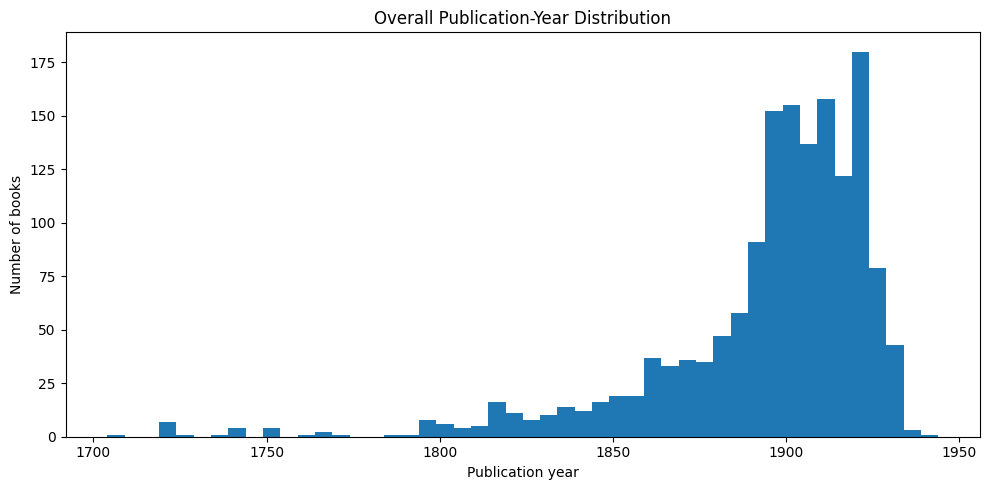

In [43]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_time["publication_year"],
    bins=range(
        df_time["publication_year"].min(),
        df_time["publication_year"].max() + 6,
        5
    )
)

plt.xlabel("Publication year")
plt.ylabel("Number of books")
plt.title("Overall Publication-Year Distribution")
plt.tight_layout()
plt.show()

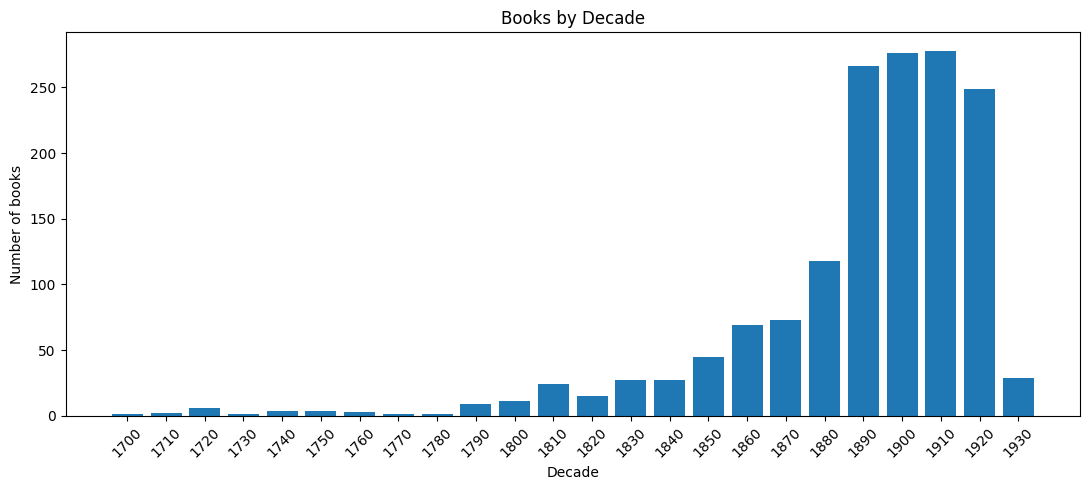

In [44]:
df_time["decade"] = (
    df_time["publication_year"] // 10 * 10
)

overall_decade_counts = (
    df_time
    .groupby("decade")
    .size()
    .rename("n_books")
    .reset_index()
)

plt.figure(figsize=(11, 5))

plt.bar(
    overall_decade_counts["decade"].astype(str),
    overall_decade_counts["n_books"]
)

plt.xlabel("Decade")
plt.ylabel("Number of books")
plt.title("Books by Decade")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Distribution by analysis group


In [45]:
auto_group_year_summary = (
    df_time
    .groupby("auto_group")["publication_year"]
    .agg(
        n_books="count",
        min_year="min",
        median_year="median",
        mean_year="mean",
        max_year="max"
    )
    .sort_values("median_year")
)

auto_group_year_summary

,n_books,min_year,median_year,mean_year,max_year
auto_group,,,,,
general_19c_english,104,1800,1887.0,1879.057692,1913
canonical_other,122,1796,1895.5,1880.286885,1929
domestic_adjacent_hybrid,42,1800,1901.0,1896.523810,1930
non_domestic_genre,808,1704,1903.5,1894.925743,1939
core_domestic,463,1740,1906.0,1898.850972,1930


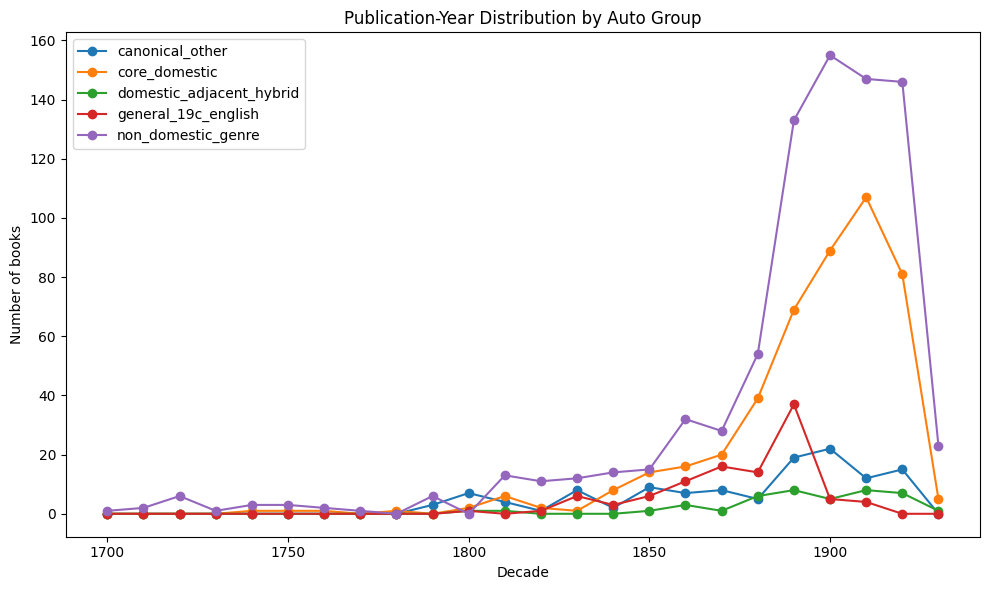

In [46]:
auto_group_decade_counts = pd.crosstab(
    df_time["decade"],
    df_time["auto_group"]
)
plt.figure(figsize=(10, 6))

for group in auto_group_decade_counts.columns:
    plt.plot(
        auto_group_decade_counts.index,
        auto_group_decade_counts[group],
        marker="o",
        label=group
    )

plt.xlabel("Decade")
plt.ylabel("Number of books")
plt.title("Publication-Year Distribution by Auto Group")
plt.legend()
plt.tight_layout()
plt.show()

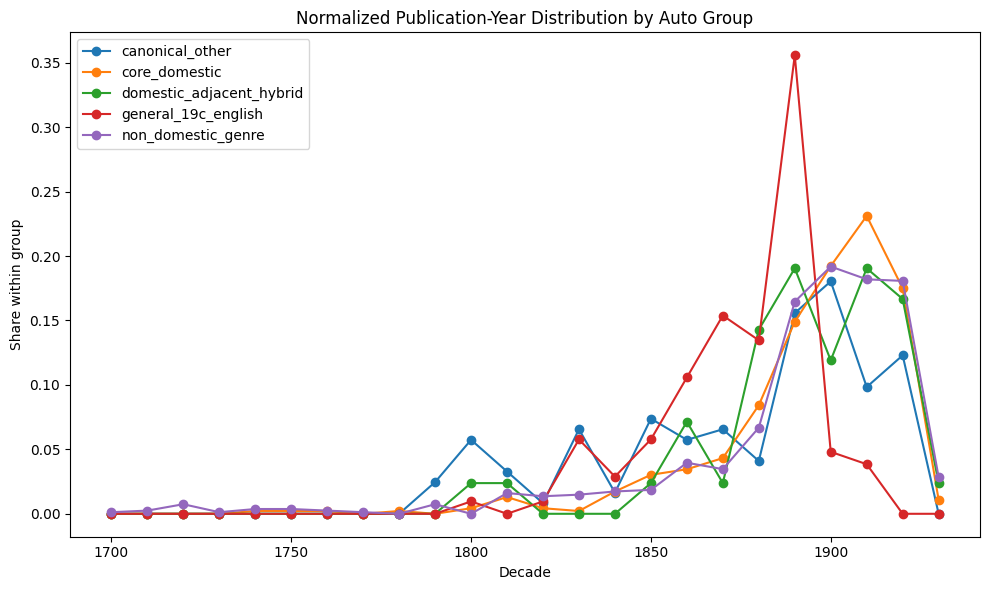

In [47]:
auto_group_decade_share = (
    auto_group_decade_counts
    .div(auto_group_decade_counts.sum(axis=0), axis=1)
)

plt.figure(figsize=(10, 6))

for group in auto_group_decade_share.columns:
    plt.plot(
        auto_group_decade_share.index,
        auto_group_decade_share[group],
        marker="o",
        label=group
    )

plt.xlabel("Decade")
plt.ylabel("Share within group")
plt.title("Normalized Publication-Year Distribution by Auto Group")
plt.legend()
plt.tight_layout()
plt.show()

### Domestic

In [48]:
df_domestic = df_time[
    df_time["is_domestic"] == 1
].copy()

print("Domestic books:", len(df_domestic))
print(df_domestic["publication_year"].describe())

Domestic books: 505
count     505.000000
mean     1898.657426
std        26.526931
min      1740.000000
25%      1890.000000
50%      1906.000000
75%      1917.000000
max      1930.000000
Name: publication_year, dtype: float64


In [50]:
df_domestic["decade"] = (
    df_domestic["publication_year"] // 10 * 10
)

domestic_decade_counts = (
    df_domestic
    .groupby("decade")
    .size()
    .rename("n_books")
    .reset_index()
)

domestic_decade_counts

,decade,n_books
0,1740,1
1,1750,1
2,1760,1
3,1780,1
4,1800,3
5,1810,7
6,1820,2
7,1830,1
8,1840,8
9,1850,15


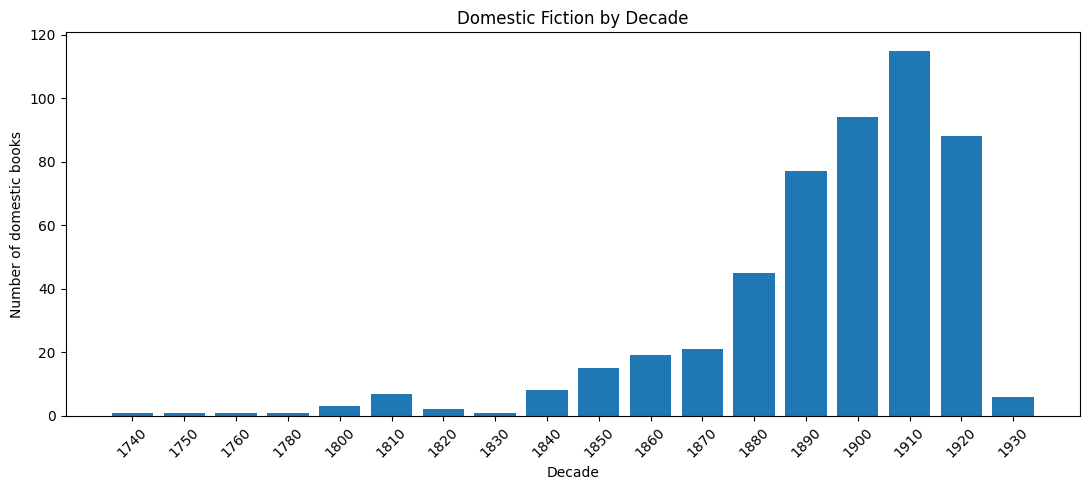

In [51]:
plt.figure(figsize=(11, 5))

plt.bar(
    domestic_decade_counts["decade"].astype(str),
    domestic_decade_counts["n_books"]
)

plt.xlabel("Decade")
plt.ylabel("Number of domestic books")
plt.title("Domestic Fiction by Decade")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Historical-period bins


In [53]:
df_time["time_period"] = pd.cut(
    df_time["publication_year"],
    bins=[
        float("-inf"),
        1809,
        1900,
        float("inf")
    ],
    labels=[
        "Before 1810",
        "1810–1900",
        "After 1900"
    ],
    ordered=True
)
df_time["time_period"].value_counts(sort=False)

,count
time_period,
Before 1810,43
1810–1900,688
After 1900,808


In [58]:
period_order = [
    "Before 1810",
    "1810–1900",
    "After 1900"
]

auto_group_time_counts = (
    auto_group_time_counts
    .reindex(columns=period_order, fill_value=0)
)

auto_group_time_counts

time_period,Before 1810,1810–1900,After 1900
auto_group,,,
canonical_other,10,63,49
core_domestic,6,186,271
domestic_adjacent_hybrid,1,20,21
general_19c_english,1,95,8
non_domestic_genre,25,324,459


In [59]:
auto_group_time_share = (
    auto_group_time_counts[period_order]
    .div(
        auto_group_time_counts[period_order].sum(axis=1),
        axis=0
    )
)

auto_group_time_share

time_period,Before 1810,1810–1900,After 1900
auto_group,,,
canonical_other,0.081967,0.516393,0.401639
core_domestic,0.012959,0.401728,0.585313
domestic_adjacent_hybrid,0.023810,0.476190,0.500000
general_19c_english,0.009615,0.913462,0.076923
non_domestic_genre,0.030941,0.400990,0.568069


## Distribution by genre


In [227]:
genre_cols = [
    "is_detective_mystery",
    "is_science_fiction",
    "is_adventure",
    "is_gothic",
    "is_historical",
]

genre_year_summary = []

for col in genre_cols:
    genre_name = col.replace("is_", "")

    sub = df_time[df_time[col] == 1]

    genre_year_summary.append({
        "genre": genre_name,
        "n_books": len(sub),
        "min_year": sub["publication_year"].min(),
        "median_year": sub["publication_year"].median(),
        "mean_year": sub["publication_year"].mean(),
        "max_year": sub["publication_year"].max(),
    })

genre_year_summary = (
    pd.DataFrame(genre_year_summary)
    .sort_values("median_year")
)

genre_year_summary

,genre,n_books,min_year,median_year,mean_year,max_year
3,gothic,82,1741,1889.5,1869.463415,1927
4,historical,181,1704,1896.0,1884.248619,1930
2,adventure,274,1704,1900.0,1890.408759,1939
1,science_fiction,66,1818,1906.5,1901.378788,1930
0,detective_mystery,297,1846,1914.0,1910.895623,1939


In [228]:
genre_decade_counts = {}

for col in genre_cols:
    genre_name = col.replace("is_", "")

    counts = (
        df_time[df_time[col] == 1]
        .groupby("decade")
        .size()
    )

    genre_decade_counts[genre_name] = counts

genre_decade_counts = (
    pd.DataFrame(genre_decade_counts)
    .fillna(0)
    .astype(int)
    .sort_index()
)

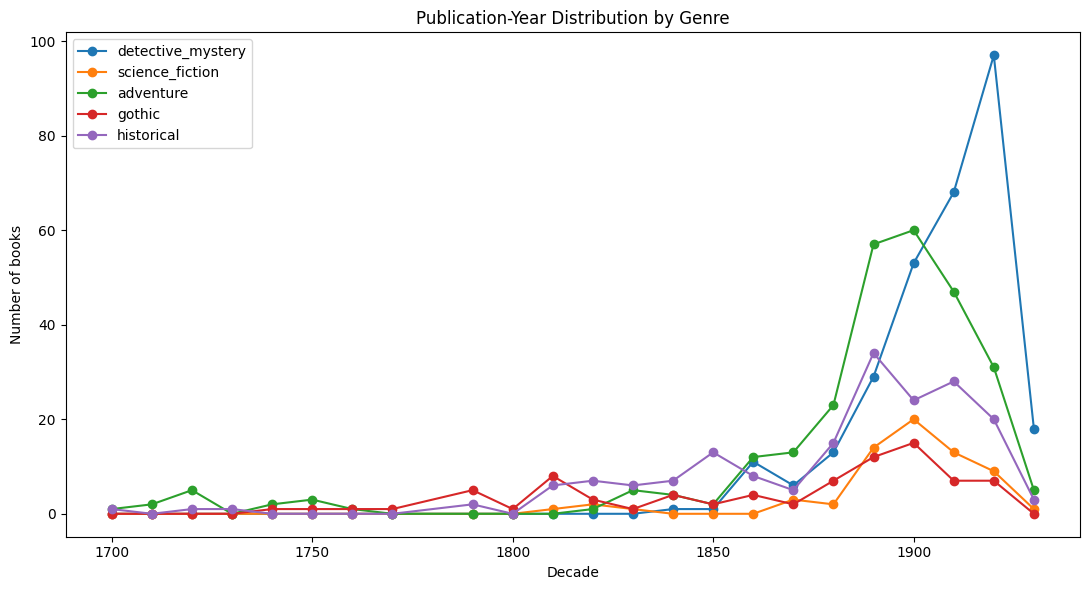

In [229]:
plt.figure(figsize=(11, 6))

for genre in genre_decade_counts.columns:
    plt.plot(
        genre_decade_counts.index,
        genre_decade_counts[genre],
        marker="o",
        label=genre
    )

plt.xlabel("Decade")
plt.ylabel("Number of books")
plt.title("Publication-Year Distribution by Genre")
plt.legend()
plt.tight_layout()
plt.show()

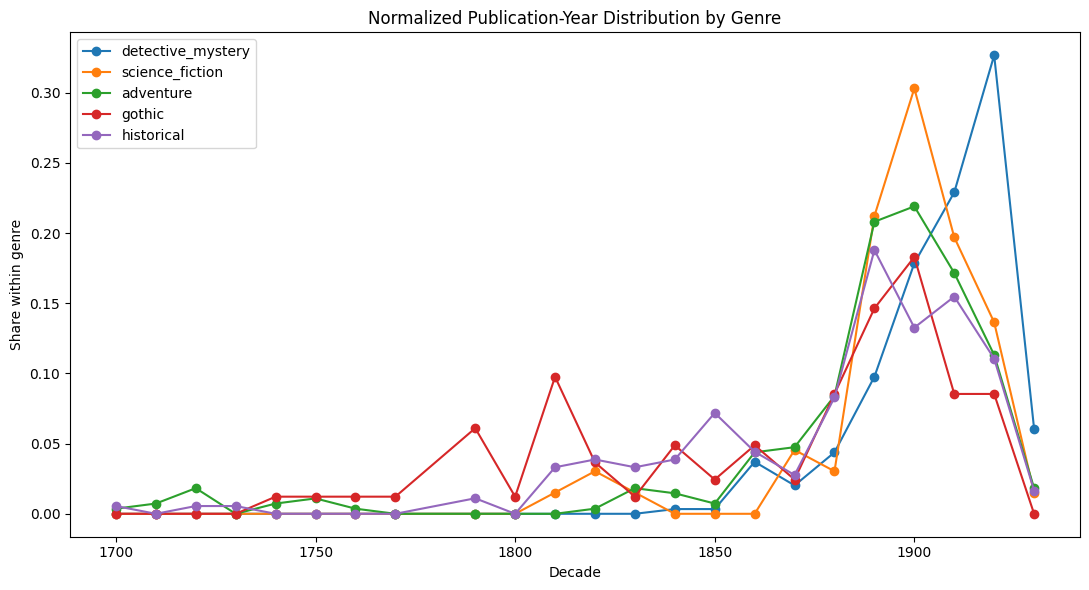

In [230]:
genre_decade_share = (
    genre_decade_counts
    .div(genre_decade_counts.sum(axis=0), axis=1)
)

plt.figure(figsize=(11, 6))

for genre in genre_decade_share.columns:
    plt.plot(
        genre_decade_share.index,
        genre_decade_share[genre],
        marker="o",
        label=genre
    )

plt.xlabel("Decade")
plt.ylabel("Share within genre")
plt.title("Normalized Publication-Year Distribution by Genre")
plt.legend()
plt.tight_layout()
plt.show()

In [231]:
comparison_cols = {
    "domestic": "is_domestic",
    "detective_mystery": "is_detective_mystery",
    "science_fiction": "is_science_fiction",
    "adventure": "is_adventure",
    "gothic": "is_gothic",
    "historical": "is_historical",
}

comparison_decade_counts = {}

for label, col in comparison_cols.items():
    counts = (
        df_time[df_time[col] == 1]
        .groupby("decade")
        .size()
    )

    comparison_decade_counts[label] = counts

comparison_decade_counts = (
    pd.DataFrame(comparison_decade_counts)
    .fillna(0)
    .astype(int)
    .sort_index()
)

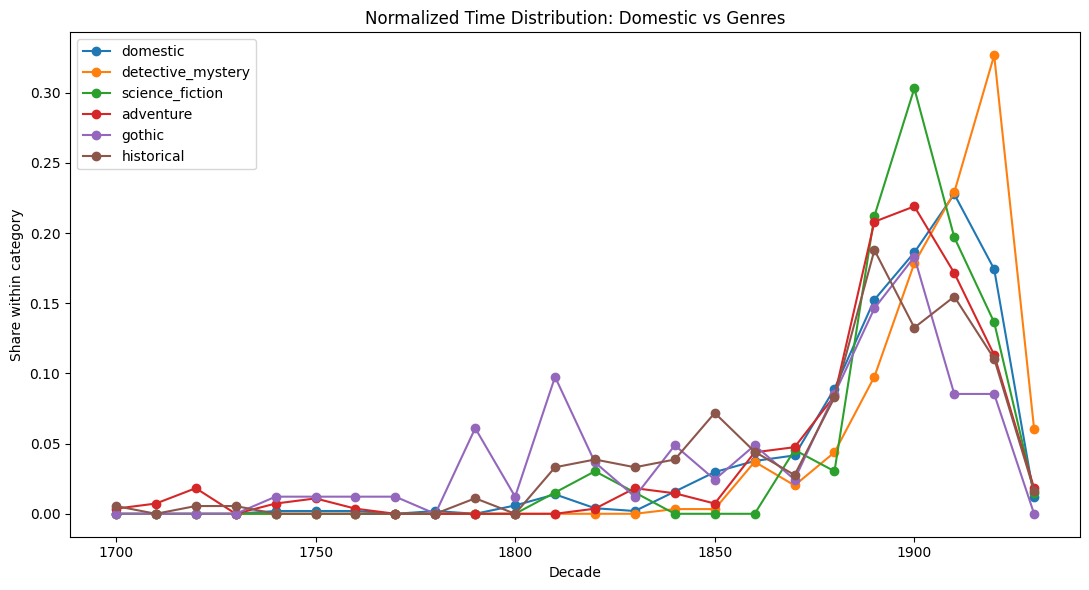

In [232]:
comparison_decade_share = (
    comparison_decade_counts
    .div(comparison_decade_counts.sum(axis=0), axis=1)
)

plt.figure(figsize=(11, 6))

for label in comparison_decade_share.columns:
    plt.plot(
        comparison_decade_share.index,
        comparison_decade_share[label],
        marker="o",
        label=label
    )

plt.xlabel("Decade")
plt.ylabel("Share within category")
plt.title("Normalized Time Distribution: Domestic vs Genres")
plt.legend()
plt.tight_layout()
plt.show()

## Armstrong core-set matching


In [62]:
core = pd.read_csv('Armstrong_index_books.csv')
len(core)

29

In [61]:
df_time

,gutenberg_id,title,publication_year,author_raw,author_display,author_query,gender,nationality,subjects,subject_text,...,has_multi_volume_phrase,volume_number,stated_total_volumes,volume_base_title,volume_base_title_key,is_volume_related,volume_family_key,author_book_count,decade,time_period
0,1872,The Red House Mystery,1923,"Milne, A. A. (Alan Alexander), 1882-1956",A. A. Milne,Alan Alexander Milne,male,British,Detective and mystery stories; England -- Fiction,detective and mystery stories; england -- fiction,...,False,<NA>,<NA>,The Red House Mystery,the red house mystery,False,a. a. milne || the red house mystery,1,1920,After 1900
1,54583,Brian Fitz-Count: A Story of Wallingford Castle and Dorchester Abbey,1888,"Crake, A. D. (Augustine David), 1836-1890",A. D. Crake,Augustine David Crake,male,British,"Historical fiction; Dorchester Abbey -- Fiction; Wallingford Castle (Wallingford, England) -- Fiction","historical fiction; dorchester abbey -- fiction; wallingford castle (wallingford, england) -- fiction",...,False,<NA>,<NA>,Brian Fitz-Count: A Story of Wallingford Castle and Dorchester Abbey,brian fitz count a story of wallingford castle and dorchester abbey,False,a. d. crake || brian fitz count a story of wallingford castle and dorchester abbey,2,1880,1810–1900
2,13215,Edwy the Fair or the First Chronicle of Aescendune\nA Tale of the Days of Saint Dunstan,1890,"Crake, A. D. (Augustine David), 1836-1890",A. D. Crake,Augustine David Crake,male,British,"Historical fiction; Edwy, King of England, -959 -- Juvenile fiction; Dunstan, Saint, 909-988 -- Juvenile fiction","historical fiction; edwy, king of england, -959 -- juvenile fiction; dunstan, saint, 909-988 -- juvenile fiction",...,False,<NA>,<NA>,Edwy the Fair or the First Chronicle of Aescendune A Tale of the Days of Saint Dunstan,edwy the fair or the first chronicle of aescendune a tale of the days of saint dunstan,False,a. d. crake || edwy the fair or the first chronicle of aescendune a tale of the days of saint dunstan,2,1890,1810–1900
3,4745,At the Villa Rose,1920,"Mason, A. E. W. (Alfred Edward Woodley), 1865-1948",A. E. W. Mason,Alfred Edward Woodley Mason,male,British,Fiction; Detective and mystery stories,fiction; detective and mystery stories,...,False,<NA>,<NA>,At the Villa Rose,at the villa rose,False,a. e. w. mason || at the villa rose,11,1920,After 1900
4,13567,Clementina,1901,"Mason, A. E. W. (Alfred Edward Woodley), 1865-1948; Partridge, Bernard, 1861-1945 [Illustrator]",A. E. W. Mason,Alfred Edward Woodley Mason,male,British,Historical fiction; English fiction,historical fiction; english fiction,...,False,<NA>,<NA>,Clementina,clementina,False,a. e. w. mason || clementina,11,1900,After 1900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1534,169,The Well at the World's End: A Tale,1896,"Morris, William, 1834-1896",William Morris,William Morris,male,British,Fantasy fiction; Quests (Expeditions) -- Fiction,fantasy fiction; quests (expeditions) -- fiction,...,False,<NA>,<NA>,The Well at the World's End: A Tale,the well at the world s end a tale,False,william morris || the well at the world s end a tale,10,1890,1810–1900
1535,3055,The Wood Beyond the World,1913,"Morris, William, 1834-1896",William Morris,William Morris,male,British,Fantasy fiction,fantasy fiction,...,False,<NA>,<NA>,The Wood Beyond the World,the wood beyond the world,False,william morris || the wood beyond the world,10,1910,After 1900
1536,17973,"The World of Romance\nbeing Contributions to The Oxford and Cambridge Magazine, 1856",1856,"Morris, William, 1834-1896",William Morris,William Morris,male,British,Middle Ages -- Fiction; Tales,middle ages -- fiction; tales,...,False,<NA>,<NA>,"The World of Romance being Contributions to The Oxford and Cambridge Magazine, 1856",the world of romance being contributions to the oxford and cambridge magazine 1856,False,william morris || the world of romance being contributions to the oxford and cambridge magazine 1856,1

In [63]:
df_time = df_time.copy()
core_df = core.copy()

# Make sure Gutenberg IDs use the same type
df_time["gutenberg_id"] = pd.to_numeric(
    df_time["gutenberg_id"],
    errors="coerce"
).astype("Int64")

core_df["gutenberg_id"] = pd.to_numeric(
    core_df["gutenberg_id"],
    errors="coerce"
).astype("Int64")

core_ids = set(
    core_df["gutenberg_id"]
    .dropna()
    .unique()
)

df_time["is_armstrong_indexed"] = (
    df_time["gutenberg_id"]
    .isin(core_ids)
    .astype(int)
)

In [64]:
n_core_rows = len(core_df)
n_unique_core_ids = core_df["gutenberg_id"].nunique()

n_matched_core_ids = (
    df_time.loc[
        df_time["is_armstrong_indexed"] == 1,
        "gutenberg_id"
    ]
    .nunique()
)

print("Core dataframe rows:", n_core_rows)
print("Unique core Gutenberg IDs:", n_unique_core_ids)
print("Core IDs matched in df_time:", n_matched_core_ids)
print("All core IDs matched:", n_matched_core_ids == n_unique_core_ids)

Core dataframe rows: 29
Unique core Gutenberg IDs: 29
Core IDs matched in df_time: 18
All core IDs matched: False


In [65]:
df_core_unmatched = core_df[
    ~core_df["gutenberg_id"].isin(
        df_time["gutenberg_id"]
    )
].copy()

print("Unmatched core books:", len(df_core_unmatched))

df_core_unmatched[
    [
        "gutenberg_id",
        "title",
        "author_display"
    ]
] if {"title", "author_display"}.issubset(df_core_unmatched.columns) else df_core_unmatched

Unmatched core books: 11


,gutenberg_id,index_title,index_author,year,gutenberg_title,gutenberg_author,category,published_year,notes,narrative_mode
4,9296,Clarissa,Richardson,NaN,Clarissa Harlowe; or the history of a young la...,"Richardson, Samuel",core_domestic,1748,NaN,epistolary
5,6593,Tom Jones,Fielding,1749.0,"History of Tom Jones, a Foundling","Fielding, Henry",contrast,1749,NaN,third_person
6,6053,Evelina,Burney,NaN,"Evelina, Or, the History of a Young Lady's Ent...","Burney, Fanny",core_domestic,1778,NaN,epistolary
8,42671,Pride and Prejudice,Austen,NaN,Pride and Prejudice,"Austen, Jane",core_domestic,1813,NaN,third_person
14,730,Oliver Twist,Dickens,NaN,Oliver Twist,"Dickens, Charles",domestic_adjacent,1838,NaN,third_person
17,599,Vanity Fair,Thackeray,NaN,Vanity Fair,"Thackeray, William Makepeace",domestic_adjacent,1848,NaN,third_person
20,1023,Bleak House,Dickens,NaN,Bleak House,"Dickens, Charles",core_domestic,1853,NaN,mixed
21,9182,Villette,Brontë,NaN,Villette,"Brontë, Charlotte",core_domestic,1853,NaN,first_person
22,786,Hard Times,Dickens,NaN,Hard Times,"Dickens, Charles",domestic_adjacent,1854,NaN,third_person
24,1400,Great Expectations,Dickens,NaN,Great Expectations,"Dickens, Charles",core_domestic,1861,NaN,first_person


In [80]:
import re
import unicodedata

def normalize_title_for_match(title):
    if pd.isna(title):
        return ""

    title = unicodedata.normalize("NFKD", str(title))
    title = "".join(
        ch for ch in title
        if not unicodedata.combining(ch)
    )

    title = title.casefold()

    # Normalize punctuation and separators
    title = re.sub(r"[—–‐-]+", " ", title)
    title = re.sub(r"[^a-z0-9\s]", " ", title)

    # Remove common leading articles
    title = re.sub(r"^(the|a|an)\s+", "", title)

    # Remove common subtitle connectors
    title = re.sub(r"\b(or|being|a tale of|the history of)\b", " ", title)

    title = re.sub(r"\s+", " ", title).strip()

    return title


def normalize_author_for_match(author):
    if pd.isna(author):
        return ""

    author = unicodedata.normalize("NFKD", str(author))
    author = "".join(
        ch for ch in author
        if not unicodedata.combining(ch)
    )

    author = author.casefold()
    author = re.sub(r"[^a-z\s]", " ", author)
    author = re.sub(r"\s+", " ", author).strip()

    return author

In [81]:
df_core_unmatched = df_core_unmatched.copy()
df_time = df_time.copy()

df_core_unmatched["title_match_key"] = (
    df_core_unmatched["gutenberg_title"]
    .fillna(df_core_unmatched["index_title"])
    .apply(normalize_title_for_match)
)

df_core_unmatched["author_match_key"] = (
    df_core_unmatched["gutenberg_author"]
    .fillna(df_core_unmatched["index_author"])
    .apply(normalize_author_for_match)
)

df_time["title_match_key"] = (
    df_time["title"]
    .apply(normalize_title_for_match)
)

df_time["author_match_key"] = (
    df_time["author_display"]
    .apply(normalize_author_for_match)
)

exact_title_matches = df_core_unmatched.merge(
    df_time[
        [
            "gutenberg_id",
            "title",
            "author_display",
            "publication_year",
            "auto_group",
            "title_match_key",
            "author_match_key",
        ]
    ],
    on="title_match_key",
    how="left",
    suffixes=("_core", "_candidate")
)

In [82]:
exact_title_matches_found = exact_title_matches[
    exact_title_matches["gutenberg_id_candidate"].notna()
].copy()

exact_title_matches_found[
    [
        "gutenberg_id_core",
        "gutenberg_title",
        "index_author",
        "gutenberg_id_candidate",
        "title",
        "author_display",
        "publication_year",
        "auto_group",
    ]
]

,gutenberg_id_core,gutenberg_title,index_author,gutenberg_id_candidate,title,author_display,publication_year,auto_group
3,42671,Pride and Prejudice,Austen,1342,Pride and Prejudice,Jane Austen,1813.0,core_domestic


In [84]:
#!pip install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 36.6 MB/s eta 0:00:00


In [85]:
from rapidfuzz import fuzz
fuzzy_results = []

for _, core_row in df_core_unmatched.iterrows():
    core_title = core_row["title_match_key"]
    core_author = core_row["author_match_key"]

    candidates = df_time.copy()

    # Prefer same author when possible
    same_author = candidates[
        candidates["author_match_key"] == core_author
    ]

    if not same_author.empty:
        candidates = same_author

    for _, candidate_row in candidates.iterrows():
        title_score = fuzz.token_set_ratio(
            core_title,
            candidate_row["title_match_key"]
        )

        author_score = fuzz.token_set_ratio(
            core_author,
            candidate_row["author_match_key"]
        )

        fuzzy_results.append({
            "core_gutenberg_id": core_row["gutenberg_id"],
            "core_title": core_row["gutenberg_title"],
            "core_index_title": core_row["index_title"],
            "core_author": core_row["index_author"],
            "core_year": core_row["published_year"],

            "candidate_gutenberg_id": candidate_row["gutenberg_id"],
            "candidate_title": candidate_row["title"],
            "candidate_author": candidate_row["author_display"],
            "candidate_year": candidate_row["publication_year"],
            "candidate_auto_group": candidate_row["auto_group"],

            "title_score": title_score,
            "author_score": author_score,
        })

df_fuzzy_matches = pd.DataFrame(fuzzy_results)

In [86]:
df_fuzzy_top5 = (
    df_fuzzy_matches
    .sort_values(
        [
            "core_gutenberg_id",
            "title_score",
            "author_score",
        ],
        ascending=[True, False, False]
    )
    .groupby("core_gutenberg_id")
    .head(5)
    .reset_index(drop=True)
)

df_fuzzy_top5[
    [
        "core_gutenberg_id",
        "core_title",
        "core_author",
        "candidate_gutenberg_id",
        "candidate_title",
        "candidate_author",
        "candidate_year",
        "title_score",
        "author_score",
    ]
]

,core_gutenberg_id,core_title,core_author,candidate_gutenberg_id,candidate_title,candidate_author,candidate_year,title_score,author_score
0,599,Vanity Fair,Thackeray,2773,Fraternity,John Galsworthy,1909,66.666667,23.809524
1,599,Vanity Fair,Thackeray,36538,Playing With Fire,Amelia E. Barr,1914,57.142857,35.000000
2,599,Vanity Fair,Thackeray,40361,The Air Pirate,Guy Thorne,1919,57.142857,21.621622
3,599,Vanity Fair,Thackeray,79009,A servant of reality,Phyllis Bottome,1919,55.172414,38.095238
4,599,Vanity Fair,Thackeray,62820,The Fire Within,Patricia Wentworth,1913,54.545455,31.111111
5,730,Oliver Twist,Dickens,2472,White Lies,Charles Reade,1860,63.636364,71.428571
6,730,Oliver Twist,Dickens,56013,The White Dove,William John Locke,1899,63.636364,30.303030
7,730,Oliver Twist,Dickens,459,The White People,Frances Hodgson Burnett,1926,58.333333,31.578947
8,730,Oliver Twist,Dickens,43492,The Five Knots,Fred M. White,1908,54.545455,37.037037
9,730,Oliver Twist,Dickens,26519,To Love,Margaret Peterson,1917,52.631579,37.500000


In [87]:
import pandas as pd

# These IDs identify the corresponding current and core-set records.
pride_candidate_id = 1342   # Current ID in df_time
pride_core_id = 42671       # ID used in core_df

pride_candidate_rows = df_time[
    df_time["gutenberg_id"] == pride_candidate_id
]

print("Rows found in df_time:", len(pride_candidate_rows))

pride_candidate_rows[
    [
        "gutenberg_id",
        "title",
        "author_display",
        "publication_year",
        "auto_group",
    ]
]

df_time.loc[
    df_time["gutenberg_id"] == pride_candidate_id,
    "gutenberg_id"
] = pride_core_id

df_time.loc[
    df_time["gutenberg_id"] == pride_core_id,
    "is_armstrong_indexed"
] = 1

Rows found in df_time: 1


In [88]:
df_core_to_add = df_core_unmatched[
    df_core_unmatched["gutenberg_id"] != pride_core_id
].copy()

print("Core books to add:", len(df_core_to_add))

Core books to add: 10


In [90]:
df_core_to_add_prepared = pd.DataFrame({
    "gutenberg_id": pd.to_numeric(
        df_core_to_add["gutenberg_id"],
        errors="coerce"
    ).astype("Int64"),

    "title": (
        df_core_to_add["gutenberg_title"]
        .fillna(df_core_to_add["index_title"])
    ),

    "author_raw": df_core_to_add["gutenberg_author"],

    # Use the available core author field for this historical matching step.
    # The cleaned author name is not required for this matching pass.
    "author_display": df_core_to_add["index_author"],

    "publication_year": pd.to_numeric(
        df_core_to_add["published_year"]
        .fillna(df_core_to_add["year"]),
        errors="coerce"
    ),

    "auto_group": pd.NA,

    "armstrong_category": df_core_to_add["category"],

    "narrative_mode": df_core_to_add["narrative_mode"],

    "is_armstrong_indexed": 1,
})

In [91]:
# Add any new core-specific columns to df_time first
for col in df_core_to_add_prepared.columns:
    if col not in df_time.columns:
        df_time[col] = pd.NA

# Add all df_time columns missing from the core rows
for col in df_time.columns:
    if col not in df_core_to_add_prepared.columns:
        df_core_to_add_prepared[col] = pd.NA

# Use exactly the same column order
df_core_to_add_prepared = df_core_to_add_prepared[
    df_time.columns
]

In [93]:
df_time_updated = pd.concat(
    [
        df_time,
        df_core_to_add_prepared
    ],
    ignore_index=True
)

/tmp/ipykernel_735/128802737.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_time_updated = pd.concat(
/tmp/ipykernel_735/128802737.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_time_updated = pd.concat(


In [94]:
print("Before adding core books:", len(df_time))
print("Core books added:", len(df_core_to_add_prepared))
print("After adding core books:", len(df_time_updated))

Before adding core books: 1539
Core books added: 10
After adding core books: 1549


AttributeError: module 'pandas' has no attribute 'to_csv'

In [99]:
df_time_updated.to_csv(
    "final_booklist1549.csv",
    index=False
)


In [101]:
df_new_candidates = df_time_updated[df_time_updated['is_armstrong_indexed']==0]

In [103]:
df_new_candidates.to_csv(
    "final_candidates_1520.csv",
    index=False
)
